# 01 — Prétraitement

Bloc 2 du projet : doublons, valeurs manquantes, valeurs aberrantes, choix des genres, normalisation.
Les calculs sont dans `src/spotify_eda/preprocessing.py` ; ce notebook sert à les lancer, à regarder les résultats et à **justifier chaque choix** (le sujet l'exige).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent          # dossier du dépôt (ce notebook est dans notebooks/)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

from spotify_eda import config
from spotify_eda.preprocessing import load_raw, clean, select_genres, standardize

pd.set_option("display.max_columns", 30)

## 1. Chargement

In [2]:
raw = load_raw(ROOT / "data" / "raw" / "dataset.csv")
print(raw.shape)
raw.head()

(114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## 2. Valeurs manquantes
Mon commentaire : quelles colonnes ont des manquants, combien, et pourquoi on peut retirer ces lignes sans biais.

In [3]:
manquants = raw.isna().sum()
manquants[manquants > 0]

artists       1
album_name    1
track_name    1
dtype: int64

## 3. Doublons
Un même `track_id` peut figurer dans **plusieurs genres** (le même titre classé dans deux genres). C'est différent d'un vrai doublon (même titre, même genre).

In [4]:
print("track_id répétés (tous genres confondus) :", raw["track_id"].duplicated().sum())
print("même titre dans le même genre             :", raw.duplicated(["track_id", "track_genre"]).sum())

track_id répétés (tous genres confondus) : 24259
même titre dans le même genre             : 450


 Mon commentaire : pourquoi on supprime les doublons dans un même genre, et pourquoi on retire de la partie supervisée les titres présents dans plusieurs des genres retenus (étiquette ambiguë).

## 4. Valeurs aberrantes

durée < 30 s : 17 | durée > 20 min : 81 | tempo = 0 : 157


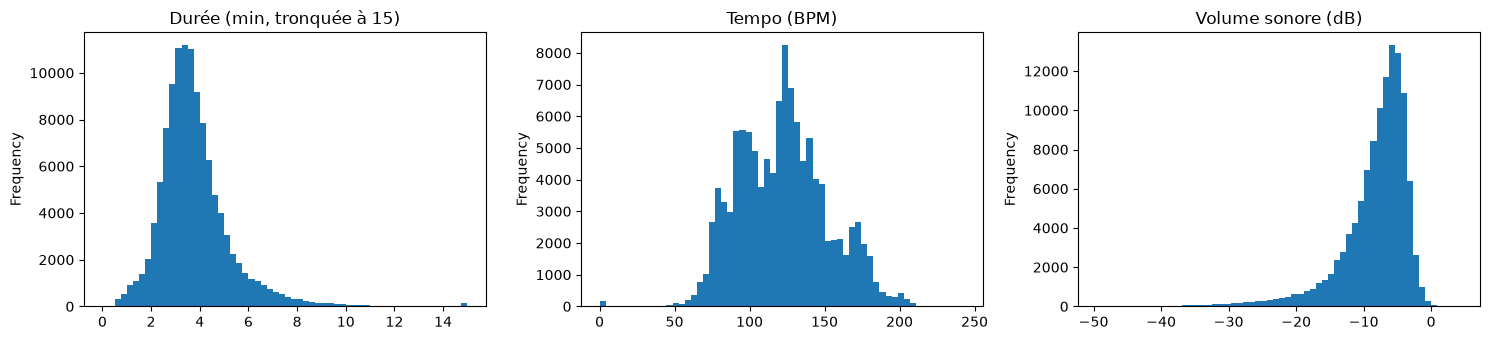

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
raw["duration_ms"].div(60_000).clip(upper=15).plot.hist(bins=60, ax=axes[0], title="Durée (min, tronquée à 15)")
raw["tempo"].plot.hist(bins=60, ax=axes[1], title="Tempo (BPM)")
raw["loudness"].plot.hist(bins=60, ax=axes[2], title="Volume sonore (dB)")
plt.tight_layout()
print("durée < 30 s :", (raw["duration_ms"] < config.MIN_DURATION_MS).sum(),
      "| durée > 20 min :", (raw["duration_ms"] > config.MAX_DURATION_MS).sum(),
      "| tempo = 0 :", (raw["tempo"] == 0).sum())

 Mon commentaire : justifier les seuils (30 s, 20 min, tempo > 0). Le volume (`loudness`) a des valeurs très basses (jusqu'à environ −47 dB) : on les **garde**, car elles correspondent à des morceaux réellement très calmes (à discuter).

In [6]:
df, rapport = clean(raw)
rapport

{'lignes_brutes': 114000,
 'manquants_par_colonne': {'artists': 1, 'album_name': 1, 'track_name': 1},
 'apres_manquants': 113999,
 'doublons_meme_genre': 450,
 'duree_aberrante': 95,
 'tempo_nul': 157,
 'lignes_finales': 113301}

## 5. Choix des genres
Le CSV compte 114 genres de 1 000 titres chacun. On en retient 8 **contrastés** pour que l'analyse discriminante reste interprétable.
✍️ Mon commentaire : pourquoi ces 8 genres (par exemple : du très acoustique au très énergique, du calme au dansant).

In [7]:
print(config.GENRES)
avant = df[df["track_genre"].isin(config.GENRES)]
sub = select_genres(df)
print(f"{len(avant)} titres dans les genres retenus -> {len(sub)} après retrait des titres à étiquette ambiguë")
sub["track_genre"].value_counts()

['classical', 'heavy-metal', 'hip-hop', 'jazz', 'reggae', 'techno', 'country', 'sleep']
7759 titres dans les genres retenus -> 7507 après retrait des titres à étiquette ambiguë


track_genre
country        1000
techno          999
heavy-metal     998
jazz            986
classical       907
reggae          885
hip-hop         876
sleep           856
Name: count, dtype: int64

## 6. Normalisation (z-score)

In [8]:
z, scaler = standardize(sub)
pd.DataFrame({"moyenne avant": sub[config.FEATURES].mean(), "écart-type avant": sub[config.FEATURES].std(),
              "moyenne après": z.mean().to_numpy(), "écart-type après": z.std(ddof=0).to_numpy()}).round(3)

,moyenne avant,écart-type avant,moyenne après,écart-type après
danceability,0.530,0.213,0.0,1.0
energy,0.569,0.299,-0.0,1.0
key,5.259,3.557,-0.0,1.0
loudness,-10.920,8.052,0.0,1.0
speechiness,0.075,0.072,-0.0,1.0
acousticness,0.385,0.383,0.0,1.0
instrumentalness,0.254,0.383,0.0,1.0
liveness,0.208,0.194,0.0,1.0
valence,0.418,0.267,-0.0,1.0
tempo,117.409,30.849,0.0,1.0


Mon commentaire : pourquoi normaliser (le tempo est en BPM, de 30 à 240, contre des scores de 0 à 1 : sans normalisation, le tempo dominerait l'ACP et les distances du K-means).

## 7. Sauvegarde

In [9]:
sub.to_csv(ROOT / "data" / "processed" / "tracks_genres.csv", index=False)
print("Écrit : data/processed/tracks_genres.csv")

Écrit : data/processed/tracks_genres.csv
